# Bengali Hate Speech Classification — Full Pipeline + Explainability (Google Colab)

This notebook covers **Setup → Config → Data Loading → EDA → Preprocessing → Classical ML → LIME/SHAP → Deep Learning (RNN/LSTM/CNN) → BanglaBERT → Captum Integrated Gradients → K-Means clustering → Model comparison → Top hate words → Adversarial injection test**.

Models: Logistic Regression, Linear SVC, Multinomial Naive Bayes, k-NN (classical, Section 6) + RNN, LSTM, CNN (custom PyTorch, Section 8) + BanglaBERT (`csebuetnlp/banglabert`, Section 9) — 8 supervised models total, all compared in Section 12. K-Means (Section 11) is a separate, unsupervised exploration and is not scored as a 9th classifier.

Designed to run top-to-bottom in **Google Colab**, reading/writing only to Google Drive.


## 1. Setup

In [1]:
!pip install -q shap lime transformers captum
!pip install -q -U "matplotlib>=3.11"

import importlib.metadata
import matplotlib

installed_mpl = importlib.metadata.version("matplotlib")
if matplotlib.__version__ != installed_mpl:
    raise RuntimeError(
        f"matplotlib {installed_mpl} is installed but {matplotlib.__version__} is still loaded. "
        "Restart the session (Runtime > Restart session), then Run all again."
    )
print("matplotlib", matplotlib.__version__)

matplotlib 3.11.2


In [2]:
import shutil
import os

if os.path.exists('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
!apt-get update -qq
!apt-get install -y -qq fonts-noto-core

import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

BENGALI_FONT_PATH = "/usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf"

if os.path.exists(BENGALI_FONT_PATH):
    fm.fontManager.addfont(BENGALI_FONT_PATH)
    plt.rcParams["font.family"] = ["Noto Sans Bengali", "DejaVu Sans"]
    print(f"Using Bengali font for plots: {BENGALI_FONT_PATH}")
else:
    print("Warning: Noto Sans Bengali not found — plot labels with Bengali text may not render.")
    print("Check the apt-get output above for the actual install error (e.g. package not found, no network).")

Using Bengali font for plots: /usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf


## 2. Config

In [4]:
import os
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DRIVE_BASE_DIR = "/content/drive/MyDrive/bengali_hate_speech"
DATA_DIR = os.path.join(DRIVE_BASE_DIR, "data")
MODELS_DIR = os.path.join(DRIVE_BASE_DIR, "models")
RESULTS_DIR = os.path.join(DRIVE_BASE_DIR, "results")

for d in (DATA_DIR, MODELS_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

CSV_PATH = os.path.join(DATA_DIR, "bengalisent140.csv")

TEXT_COL = "text"
LABEL_COL = "label"

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15

FORCE_RETRAIN = False

BENGALI_WORD_CHARS = r"\u0980-\u09FFA-Za-z0-9"
TOKEN_PATTERN = rf"[{BENGALI_WORD_CHARS}]+"
SPLIT_PATTERN = rf"[^{BENGALI_WORD_CHARS}]+"

## 3. Data Loading

In [5]:
import pandas as pd

df = pd.read_csv(CSV_PATH)

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
df.head()

Shape: (132451, 2)

Dtypes:
 text     object
label     int64
dtype: object


,text,label
0,ধর্ষণ চুরিডাকাতি ছিনতাইসহ সকল প্রকার অপকর্মের ...,1
1,সাজেকে গিয়ে প্রেমিকাকে কেউ তারা দেখায় আর কেউ ব...,1
2,প্রথম ভেবেছিলাম চোর ধরেছে পরে বুঝলাম কম্বল দান...,0
3,ছোট ভাইকে সিগারেট খাওয়া অবস্থায় ধরিয়ে দেওয়ার প...,0
4,শীত যে হঠাৎ করে কখন পড়ে গেল একটুও বুঝতে পারলাম...,0


## 4. EDA

### 4.1 Class balance

label
0    66039
1    66412
Name: count, dtype: int64

Imbalance ratio (majority/minority): 1.01


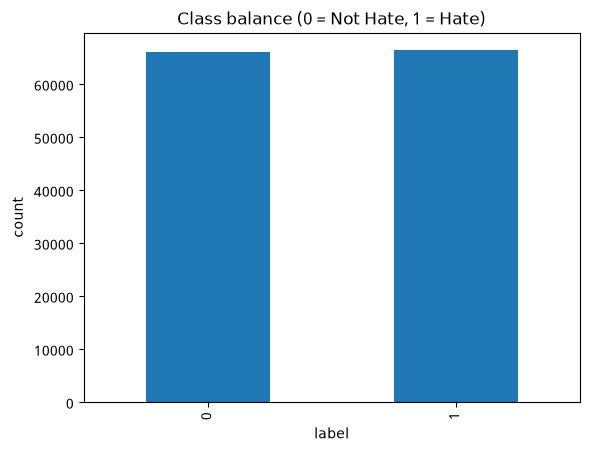

In [6]:
import matplotlib.pyplot as plt

class_counts = df[LABEL_COL].value_counts().sort_index()
print(class_counts)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nImbalance ratio (majority/minority): {imbalance_ratio:.2f}")
if imbalance_ratio > 1.5:
    print("Notable class imbalance — consider class_weight='balanced' downstream.")

class_counts.plot(kind="bar", title="Class balance (0 = Not Hate, 1 = Hate)")
plt.xlabel(LABEL_COL)
plt.ylabel("count")
plt.show()

### 4.2 Text length distribution

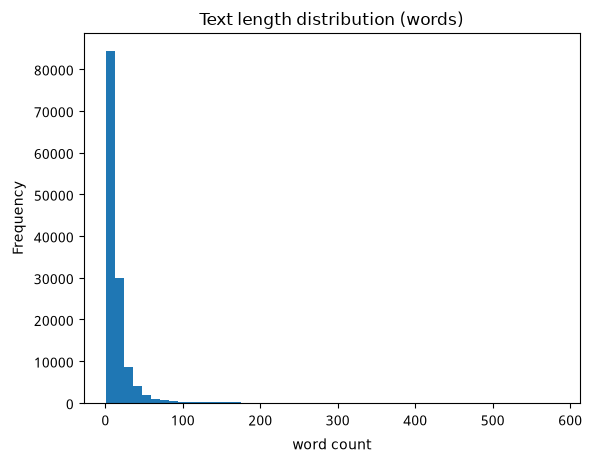

count    132451.000000
mean         14.690542
std          19.265750
min           1.000000
25%           5.000000
50%           9.000000
75%          17.000000
max         583.000000
Name: text_len, dtype: float64


In [7]:
df["text_len"] = df[TEXT_COL].astype(str).str.split().apply(len)

df["text_len"].plot(kind="hist", bins=50, title="Text length distribution (words)")
plt.xlabel("word count")
plt.show()

print(df["text_len"].describe())

### 4.3 Sample rows per class

In [8]:
for label_value in sorted(df[LABEL_COL].unique()):
    print(f"\n--- Sample rows for {LABEL_COL} = {label_value} ---")
    display(df[df[LABEL_COL] == label_value][[TEXT_COL, LABEL_COL]].sample(5, random_state=SEED))


--- Sample rows for label = 0 ---


,text,label
94366,আমি ওকে ফাসি চাই,0
85011,বাস্তবের সাথে ই মিল হয়নাই আর অভিনয় একদম বাজে হইছে,0
117809,খেলুন আর পুরুষ্কার জিতুন,0
127560,দর্শক হৃদয় জয় করার জন্য একটা নাটকে যা যা থাকা ...,0
109480,দারুন হয়েছে আমি আকাশ থেকে পড়বা সাঁতার কাটবো,0



--- Sample rows for label = 1 ---


,text,label
57609,সবই টাকা আয় এর ধান্দা কাফের গুলা,1
36753,ফাজিল মেয়ে,1
8084,নাস্তিক মুনাফিক,1
40988,ছাপা কবির কে পাব্লিক পুটকি মাইরা ছাইড়া দিছে,1
108438,কাশ্মীরে কুত্তার মতো মারখেয়ে চলেছে ভারত তাই জা...,1


## 5. Preprocessing

### 5.1 Text cleaning

In [9]:
import re
import unicodedata

def clean_text(text):
    text = str(text)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^\w\s\u0980-\u09FF]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df[TEXT_COL].apply(clean_text)
df[[TEXT_COL, "clean_text"]].head()

,text,clean_text
0,ধর্ষণ চুরিডাকাতি ছিনতাইসহ সকল প্রকার অপকর্মের ...,ধর্ষণ চুরিডাকাতি ছিনতাইসহ সকল প্রকার অপকর্মের ...
1,সাজেকে গিয়ে প্রেমিকাকে কেউ তারা দেখায় আর কেউ ব...,সাজেকে গিয়ে প্রেমিকাকে কেউ তারা দেখায় আর কেউ...
2,প্রথম ভেবেছিলাম চোর ধরেছে পরে বুঝলাম কম্বল দান...,প্রথম ভেবেছিলাম চোর ধরেছে পরে বুঝলাম কম্বল দান...
3,ছোট ভাইকে সিগারেট খাওয়া অবস্থায় ধরিয়ে দেওয়ার প...,ছোট ভাইকে সিগারেট খাওয়া অবস্থায় ধরিয়ে দেওয়...
4,শীত যে হঠাৎ করে কখন পড়ে গেল একটুও বুঝতে পারলাম...,শীত যে হঠাৎ করে কখন পড়ে গেল একটুও বুঝতে পারলা...


### 5.2 Stratified train / val / test split

In [10]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df[LABEL_COL]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=(VAL_RATIO + TEST_RATIO), stratify=y, random_state=SEED
)
relative_test_size = TEST_RATIO / (VAL_RATIO + TEST_RATIO)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=relative_test_size, stratify=y_temp, random_state=SEED
)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (92715,) Val: (19868,) Test: (19868,)


### 5.3 TF-IDF features (classical models)

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

VECTORIZER_PATH = os.path.join(MODELS_DIR, "tfidf_vectorizer.joblib")

if os.path.exists(VECTORIZER_PATH) and not FORCE_RETRAIN:
    vectorizer = joblib.load(VECTORIZER_PATH)
    print("Loaded existing TF-IDF vectorizer from Drive.")
else:
    vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), token_pattern=TOKEN_PATTERN)
    vectorizer.fit(X_train)
    joblib.dump(vectorizer, VECTORIZER_PATH)
    print("Fitted new TF-IDF vectorizer and saved to Drive.")

X_train_tfidf = vectorizer.transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape)

Fitted new TF-IDF vectorizer and saved to Drive.
(92715, 20000)


### 5.4 Tokenizer + vocab + padded sequences (deep learning models)

Shared input pipeline for the custom PyTorch models (RNN/LSTM/CNN) in Section 8. Builds a word-level vocabulary from the training split only (no leakage from val/test), reuses `TOKEN_PATTERN`/tokenization already defined in Config so tokens match the TF-IDF path, and pads/truncates every sequence to `MAX_LEN`, set to the 95th percentile of token counts in the training split (not val/test) rather than an arbitrary constant.

In [12]:
import re
import json
from collections import Counter

def tokenize_bn(text):
    return re.findall(TOKEN_PATTERN, text)

VOCAB_SIZE = 20000
train_token_counts = X_train.apply(lambda t: len(tokenize_bn(t)))
MAX_LEN = int(train_token_counts.quantile(0.95))
MAX_LEN = min(max(MAX_LEN, 16), 128)
print(f"MAX_LEN (95th percentile of training text length in tokens, clamped to [16, 128]): {MAX_LEN}")

VOCAB_PATH = os.path.join(MODELS_DIR, "vocab.json")

if os.path.exists(VOCAB_PATH) and not FORCE_RETRAIN:
    with open(VOCAB_PATH, "r", encoding="utf-8") as f:
        vocab = json.load(f)
    print(f"Loaded existing vocab (size={len(vocab)}) from Drive.")
else:
    counter = Counter()
    for text in X_train:
        counter.update(tokenize_bn(text))
    vocab = {"<pad>": 0, "<unk>": 1}
    for word, _ in counter.most_common(VOCAB_SIZE - len(vocab)):
        vocab[word] = len(vocab)
    with open(VOCAB_PATH, "w", encoding="utf-8") as f:
        json.dump(vocab, f, ensure_ascii=False)
    print(f"Built new vocab (size={len(vocab)}) and saved to Drive.")

PAD_IDX = vocab["<pad>"]
UNK_IDX = vocab["<unk>"]


def encode_text(text, max_len=MAX_LEN):
    ids = [vocab.get(tok, UNK_IDX) for tok in tokenize_bn(text)[:max_len]]
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids


X_train_seq = np.array([encode_text(t) for t in X_train])
X_val_seq = np.array([encode_text(t) for t in X_val])
X_test_seq = np.array([encode_text(t) for t in X_test])

print(X_train_seq.shape, X_val_seq.shape, X_test_seq.shape)

MAX_LEN (95th percentile of training text length in tokens, clamped to [16, 128]): 43
Built new vocab (size=20000) and saved to Drive.
(92715, 43) (19868, 43) (19868, 43)


In [13]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.manual_seed(SEED)


class TextSeqDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        x = torch.tensor(self.sequences[idx], dtype=torch.long)
        y = torch.tensor(self.labels[idx], dtype=torch.float32)
        return x, y


BATCH_SIZE = 64
train_loader = DataLoader(TextSeqDataset(X_train_seq, y_train.to_numpy()), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TextSeqDataset(X_val_seq, y_val.to_numpy()), batch_size=BATCH_SIZE)
test_loader = DataLoader(TextSeqDataset(X_test_seq, y_test.to_numpy()), batch_size=BATCH_SIZE)

Using device: cuda


## 6. Classical ML models

Shared helpers: train-or-load-from-Drive (checkpointing) and a common evaluation routine (accuracy, precision/recall/F1, confusion matrix, ROC-AUC) used by all 4 models below.

In [14]:
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)
import json

def load_or_train(model_filename, train_fn):
    path = os.path.join(MODELS_DIR, model_filename)
    if os.path.exists(path) and not FORCE_RETRAIN:
        print(f"Loading existing model from {path}")
        return joblib.load(path)
    model = train_fn()
    joblib.dump(model, path)
    print(f"Trained and saved model to {path}")
    return model

def evaluate_from_predictions(name, y_eval, y_pred, y_proba):
    acc = accuracy_score(y_eval, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_eval, y_pred, average="binary")
    roc_auc = roc_auc_score(y_eval, y_proba)
    cm = confusion_matrix(y_eval, y_pred)

    metrics = {
        "model": name, "accuracy": acc, "precision": precision,
        "recall": recall, "f1": f1, "roc_auc": roc_auc,
    }
    print(f"\n=== {name} ===")
    for k, v in metrics.items():
        if k != "model":
            print(f"{k}: {v:.4f}")

    ConfusionMatrixDisplay(cm).plot()
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

    with open(os.path.join(RESULTS_DIR, f"{name}_metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2)

    return metrics

def evaluate_model(model, name, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    return evaluate_from_predictions(name, y_eval, y_pred, y_proba)

all_metrics = {}

### 6.1 Logistic Regression

Trained and saved model to /content/drive/MyDrive/bengali_hate_speech/models/logistic_regression.joblib

=== logistic_regression ===
accuracy: 0.8232
precision: 0.8487
recall: 0.7879
f1: 0.8172
roc_auc: 0.9069


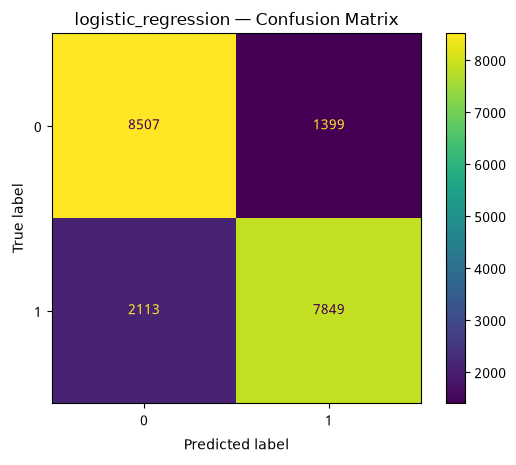

In [15]:
from sklearn.linear_model import LogisticRegression

def train_lr():
    m = LogisticRegression(max_iter=1000, random_state=SEED)
    m.fit(X_train_tfidf, y_train)
    return m

lr_model = load_or_train("logistic_regression.joblib", train_lr)
all_metrics["logistic_regression"] = evaluate_model(lr_model, "logistic_regression", X_test_tfidf, y_test)

### 6.2 Linear SVC (calibrated for `predict_proba`)

Trained and saved model to /content/drive/MyDrive/bengali_hate_speech/models/linear_svc.joblib

=== linear_svc ===
accuracy: 0.8201
precision: 0.8428
recall: 0.7881
f1: 0.8145
roc_auc: 0.9031


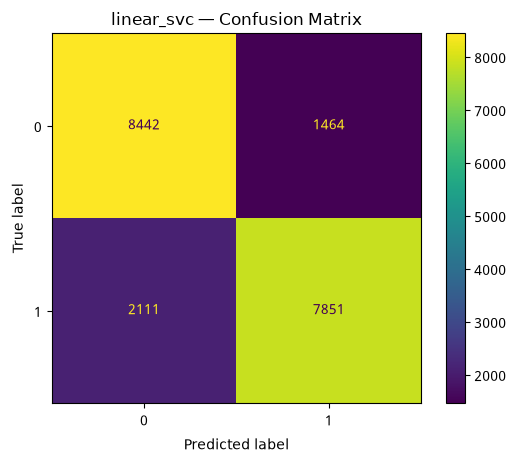

In [16]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

def train_svc():
    base = LinearSVC(random_state=SEED)
    m = CalibratedClassifierCV(base, cv=3)
    m.fit(X_train_tfidf, y_train)
    return m

svc_model = load_or_train("linear_svc.joblib", train_svc)
all_metrics["linear_svc"] = evaluate_model(svc_model, "linear_svc", X_test_tfidf, y_test)

### 6.3 Multinomial Naive Bayes

Trained and saved model to /content/drive/MyDrive/bengali_hate_speech/models/multinomial_nb.joblib

=== multinomial_nb ===
accuracy: 0.8003
precision: 0.7982
recall: 0.8054
f1: 0.8018
roc_auc: 0.8914


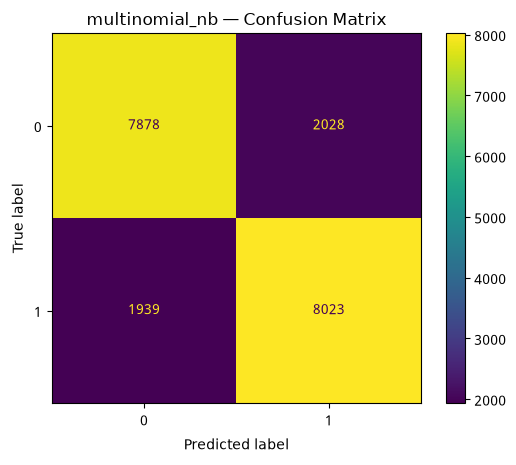

In [17]:
from sklearn.naive_bayes import MultinomialNB

def train_nb():
    m = MultinomialNB()
    m.fit(X_train_tfidf, y_train)
    return m

nb_model = load_or_train("multinomial_nb.joblib", train_nb)
all_metrics["multinomial_nb"] = evaluate_model(nb_model, "multinomial_nb", X_test_tfidf, y_test)

### 6.4 k-NN

Trained and saved model to /content/drive/MyDrive/bengali_hate_speech/models/knn.joblib

=== knn ===
accuracy: 0.6092
precision: 0.6676
recall: 0.4395
f1: 0.5300
roc_auc: 0.6661


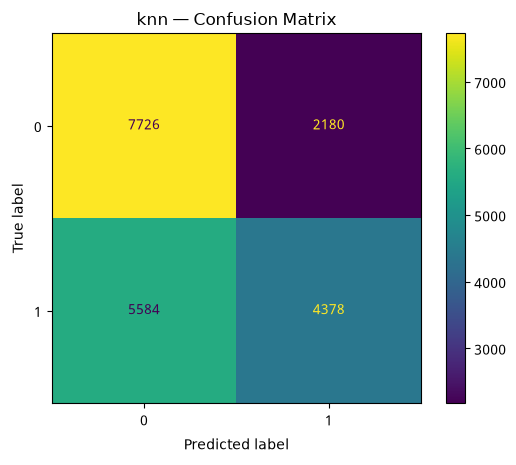

In [18]:
from sklearn.neighbors import KNeighborsClassifier

def train_knn():
    m = KNeighborsClassifier(n_neighbors=5)
    m.fit(X_train_tfidf, y_train)
    return m

knn_model = load_or_train("knn.joblib", train_knn)
all_metrics["knn"] = evaluate_model(knn_model, "knn", X_test_tfidf, y_test)

## 7. Explainability (classical models only)

### 7.1 LIME (all 4 classical models)

In [19]:
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(class_names=["Not Hate", "Hate"], split_expression=SPLIT_PATTERN)

def lime_predict_fn(model):
    def _predict(texts):
        return model.predict_proba(vectorizer.transform(texts))
    return _predict

def show_lime_explanations(model, name, texts, num_features=10):
    predict_fn = lime_predict_fn(model)
    for text in texts:
        exp = lime_explainer.explain_instance(text, predict_fn, num_features=num_features)
        print(f"\n--- LIME: {name} ---\nText: {text}")
        for word, weight in exp.as_list():
            print(f"  {word}: {weight:+.4f}")
        try:
            exp.show_in_notebook(text=True)
        except ImportError:
            pass

In [20]:
sample_texts = X_test.sample(3, random_state=SEED).tolist()

models_by_name = {
    "logistic_regression": lr_model,
    "linear_svc": svc_model,
    "multinomial_nb": nb_model,
    "knn": knn_model,
}

for name, model in models_by_name.items():
    show_lime_explanations(model, name, sample_texts, num_features=10)


--- LIME: logistic_regression ---
Text: বাকের ভাই এর মত নিশো ভাইয়ের এই চরিত্র টা অনেক অনেক ভালো লেগেছে আসলেই নাটকটা বাস্তব পরিস্থিতি তুলে ধরেছে বড়দের অন্যায় কাজের প্রতিবাদ করাটা যদি বেয়াদবি হয় তবে কম বয়সী পুলিশ কি বুড়া চোর রে ধরতে পারবে না দারুন একটা কন্সেপ্ট নিয়ে বানিয়েছে নাটক টা মূলত এমন বেয়াদব ছেলেদের দরকার আছে সমাজে বাকের ভাই ও তন্ময় এর মত প্রতিবাদি লোক গুলা সব সময়ই অপরাধী হয় সমাজের কাছে
  অনেক: -0.0562
  ভাই: -0.0521
  মত: +0.0521
  দারুন: -0.0456
  নাটকটা: -0.0415
  নাটক: -0.0390
  পুলিশ: +0.0360
  চোর: +0.0309
  নিশো: -0.0303
  লেগেছে: -0.0272


[Interactive LIME explanation - run the notebook in Colab to view it.]



--- LIME: logistic_regression ---
Text: দু সালা তরে জুতা মাড়ি শাকিব খান আছে ত
  সালা: +0.3175
  শাকিব: -0.1636
  জুতা: +0.1574
  তরে: +0.0872
  খান: -0.0537
  আছে: -0.0234
  দু: +0.0102
  ত: +0.0083
  মাড়ি: +0.0008


[Interactive LIME explanation - run the notebook in Colab to view it.]



--- LIME: logistic_regression ---
Text: চুল গুলো সুন্দরবাতাসে যদি নাড়াদিতো
  চুল: +0.1507
  গুলো: -0.0352
  যদি: -0.0256
  সুন্দরবাতাসে: -0.0020
  নাড়াদিতো: -0.0016


...

[Interactive LIME explanation - run the notebook in Colab to view it.]



--- LIME: knn ---
Text: দু সালা তরে জুতা মাড়ি শাকিব খান আছে ত
  তরে: +0.2666
  শাকিব: -0.2624
  জুতা: +0.1841
  খান: -0.1119
  ত: -0.0971
  সালা: +0.0575
  দু: -0.0237
  আছে: -0.0163
  মাড়ি: -0.0049


[Interactive LIME explanation - run the notebook in Colab to view it.]



--- LIME: knn ---
Text: চুল গুলো সুন্দরবাতাসে যদি নাড়াদিতো
  যদি: -0.3196
  চুল: +0.2238
  গুলো: +0.1757
  নাড়াদিতো: -0.0638
  সুন্দরবাতাসে: -0.0608


[Interactive LIME explanation - run the notebook in Colab to view it.]


### 7.2 SHAP

`LinearExplainer` is used for Logistic Regression, which exposes native `coef_`/`intercept_`. Scikit-learn's `MultinomialNB` does **not** expose `coef_`/`intercept_` (verified against the installed version), so it isn't compatible with `LinearExplainer` — it's grouped with Linear SVC and k-NN below under the general black-box path (`shap.Explainer` + a text masker, auto-selecting a Permutation explainer). Sample count is capped to keep runtime sane.

In [21]:
import shap

feature_names = vectorizer.get_feature_names_out()
sample_tfidf = vectorizer.transform(sample_texts)

shap_lr_explainer = shap.LinearExplainer(lr_model, X_train_tfidf)
shap_lr_values = shap_lr_explainer(sample_tfidf)

def show_shap_linear_top_words(shap_values, sample_tfidf, feature_names, texts, top_n=10):
    for i, text in enumerate(texts):
        row = sample_tfidf[i].toarray()[0]
        nonzero_idx = row.nonzero()[0]
        contributions = list(zip(feature_names[nonzero_idx], shap_values.values[i][nonzero_idx]))
        contributions.sort(key=lambda x: abs(x[1]), reverse=True)
        print(f"\nText: {text}")
        print(f"Top {top_n} SHAP word contributions (logistic_regression):")
        for word, val in contributions[:top_n]:
            print(f"  {word}: {val:+.4f}")

show_shap_linear_top_words(shap_lr_values, sample_tfidf, feature_names, sample_texts)


Text: বাকের ভাই এর মত নিশো ভাইয়ের এই চরিত্র টা অনেক অনেক ভালো লেগেছে আসলেই নাটকটা বাস্তব পরিস্থিতি তুলে ধরেছে বড়দের অন্যায় কাজের প্রতিবাদ করাটা যদি বেয়াদবি হয় তবে কম বয়সী পুলিশ কি বুড়া চোর রে ধরতে পারবে না দারুন একটা কন্সেপ্ট নিয়ে বানিয়েছে নাটক টা মূলত এমন বেয়াদব ছেলেদের দরকার আছে সমাজে বাকের ভাই ও তন্ময় এর মত প্রতিবাদি লোক গুলা সব সময়ই অপরাধী হয় সমাজের কাছে
Top 10 SHAP word contributions (logistic_regression):
  ভাই: -0.3295
  দারুন: -0.3154
  নাটকটা: -0.3032
  অনেক: -0.3013
  মত: +0.2584
  পুলিশ: +0.2484
  চোর: +0.2482
  নাটক টা: -0.2442
  নিশো: -0.2393
  ভাইয়ের: -0.1900

Text: দু সালা তরে জুতা মাড়ি শাকিব খান আছে ত
Top 10 SHAP word contributions (logistic_regression):
  সালা: +1.9031
  জুতা: +1.2177
  তরে: +0.8478
  শাকিব: -0.6856
  শাকিব খান: -0.4408
  দু: +0.2390
  ত: +0.2005
  আছে: -0.1318
  খান: +0.0886
  তরে জুতা: -0.0511

Text: চুল গুলো সুন্দরবাতাসে যদি নাড়াদিতো
Top 10 SHAP word contributions (logistic_regression):
  চুল: +0.2975
  চুল গুলো: +0.2307
  গুলো: -0.

In [22]:
def make_predict_proba_fn(model):
    def _predict(texts):
        return model.predict_proba(vectorizer.transform(texts))
    return _predict

text_masker = shap.maskers.Text(tokenizer=SPLIT_PATTERN)

def show_shap_text_explanations(model, name, texts, max_evals=200):
    predict_fn = make_predict_proba_fn(model)
    explainer = shap.Explainer(predict_fn, text_masker)
    shap_values = explainer(texts, max_evals=max_evals)
    print(f"\n--- SHAP (text masker): {name} ---")
    shap.plots.text(shap_values[:, :, 1])

for name, model in [("multinomial_nb", nb_model), ("linear_svc", svc_model), ("knn", knn_model)]:
    show_shap_text_explanations(model, name, sample_texts, max_evals=200)


--- SHAP (text masker): multinomial_nb ---


[Interactive SHAP text plot - run the notebook in Colab to view it.]



--- SHAP (text masker): linear_svc ---


[Interactive SHAP text plot - run the notebook in Colab to view it.]



--- SHAP (text masker): knn ---


[Interactive SHAP text plot - run the notebook in Colab to view it.]


**Caveat — k-NN:** k-NN's decision boundary is a local majority vote over neighbors — non-smooth, so it can flip abruptly from small word changes. LIME and SHAP both lean on an assumption of local smoothness, so k-NN's word-importance results above will look noisier and less stable run-to-run than LR/NB's. Kept in the notebook, but read with that caveat rather than the same confidence as the smoother models.

## 8. Deep Learning Models (PyTorch)

Custom RNN, LSTM and CNN classifiers over the padded token-id sequences built in 5.4, each with a trainable `nn.Embedding` (no pretrained fastText vectors, per project scope). Same checkpoint-then-load pattern as Section 6: a model already saved to Drive is loaded instead of retrained, so a disconnected Colab session doesn't cost a full re-run.

In [23]:
EMBED_DIM = 128
HIDDEN_DIM = 128
VOCAB_SIZE_ACTUAL = len(vocab)


class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, hidden = self.rnn(emb)
        return self.fc(hidden[-1]).squeeze(-1)


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, (hidden, _) = self.lstm(emb)
        return self.fc(hidden[-1]).squeeze(-1)


class CNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_filters, kernel_sizes, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([nn.Conv1d(embed_dim, num_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), 1)

    def forward(self, x):
        emb = self.embedding(x).transpose(1, 2)
        conv_outs = [torch.relu(conv(emb)).max(dim=2).values for conv in self.convs]
        cat = torch.cat(conv_outs, dim=1)
        return self.fc(self.dropout(cat)).squeeze(-1)

Shared helpers: a checkpoint-aware training loop (mirrors `load_or_train` from Section 6, but for PyTorch `state_dict`s) and an inference helper producing the same `(y_true, y_pred, y_proba)` shape `evaluate_from_predictions` expects.

In [24]:
def train_torch_model(model, name, train_loader, val_loader, epochs=5, lr=1e-3):
    ckpt_path = os.path.join(MODELS_DIR, f"{name}.pt")
    model = model.to(device)

    if os.path.exists(ckpt_path) and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        print(f"Loaded existing weights for {name} from Drive.")
        return model

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                val_loss += criterion(model(xb), yb).item() * xb.size(0)

        print(
            f"[{name}] epoch {epoch + 1}/{epochs} "
            f"train_loss={train_loss / len(train_loader.dataset):.4f} "
            f"val_loss={val_loss / len(val_loader.dataset):.4f}"
        )

    torch.save(model.state_dict(), ckpt_path)
    print(f"Trained and saved {name} to Drive.")
    return model


def get_torch_predictions(model, loader):
    model.eval()
    y_true, y_pred, y_proba = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            proba = torch.sigmoid(model(xb.to(device))).cpu().numpy()
            y_true.extend(yb.numpy().tolist())
            y_proba.extend(proba.tolist())
            y_pred.extend((proba >= 0.5).astype(int).tolist())
    return np.array(y_true), np.array(y_pred), np.array(y_proba)

### 8.1 RNN

[rnn] epoch 1/5 train_loss=0.6936 val_loss=0.6927
[rnn] epoch 2/5 train_loss=0.6947 val_loss=0.7043
[rnn] epoch 3/5 train_loss=0.6655 val_loss=0.6201
[rnn] epoch 4/5 train_loss=0.6176 val_loss=0.6030
[rnn] epoch 5/5 train_loss=0.5742 val_loss=0.5925
Trained and saved rnn to Drive.

=== rnn ===
accuracy: 0.6789
precision: 0.6709
recall: 0.7059
f1: 0.6880
roc_auc: 0.7459


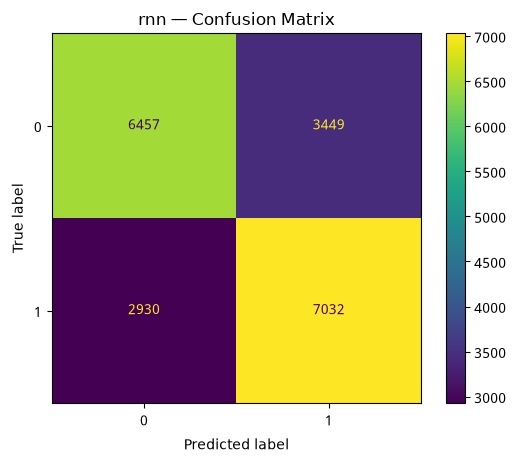

In [25]:
rnn_model = RNNClassifier(VOCAB_SIZE_ACTUAL, EMBED_DIM, HIDDEN_DIM, PAD_IDX)
rnn_model = train_torch_model(rnn_model, "rnn", train_loader, val_loader, epochs=5)

y_true, y_pred, y_proba = get_torch_predictions(rnn_model, test_loader)
all_metrics["rnn"] = evaluate_from_predictions("rnn", y_true, y_pred, y_proba)

### 8.2 LSTM

[lstm] epoch 1/5 train_loss=0.6878 val_loss=0.6800
[lstm] epoch 2/5 train_loss=0.5374 val_loss=0.4448
[lstm] epoch 3/5 train_loss=0.3904 val_loss=0.4020
[lstm] epoch 4/5 train_loss=0.3344 val_loss=0.3951
[lstm] epoch 5/5 train_loss=0.2973 val_loss=0.4241
Trained and saved lstm to Drive.

=== lstm ===
accuracy: 0.8154
precision: 0.8755
recall: 0.7365
f1: 0.8000
roc_auc: 0.9044


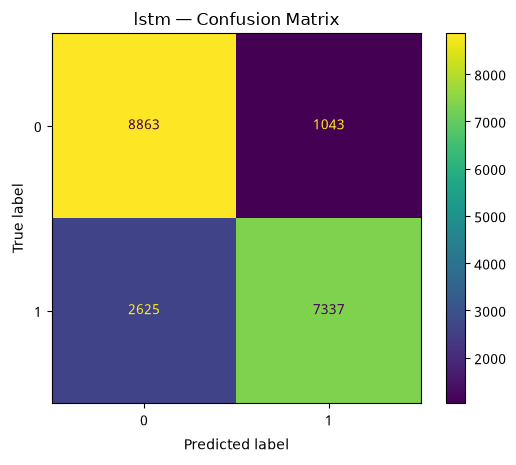

In [26]:
lstm_model = LSTMClassifier(VOCAB_SIZE_ACTUAL, EMBED_DIM, HIDDEN_DIM, PAD_IDX)
lstm_model = train_torch_model(lstm_model, "lstm", train_loader, val_loader, epochs=5)

y_true, y_pred, y_proba = get_torch_predictions(lstm_model, test_loader)
all_metrics["lstm"] = evaluate_from_predictions("lstm", y_true, y_pred, y_proba)

### 8.3 CNN

[cnn] epoch 1/5 train_loss=0.4963 val_loss=0.4173
[cnn] epoch 2/5 train_loss=0.3804 val_loss=0.3946
[cnn] epoch 3/5 train_loss=0.3275 val_loss=0.3885
[cnn] epoch 4/5 train_loss=0.2833 val_loss=0.4032
[cnn] epoch 5/5 train_loss=0.2435 val_loss=0.4239
Trained and saved cnn to Drive.

=== cnn ===
accuracy: 0.8207
precision: 0.8259
recall: 0.8141
f1: 0.8199
roc_auc: 0.9042


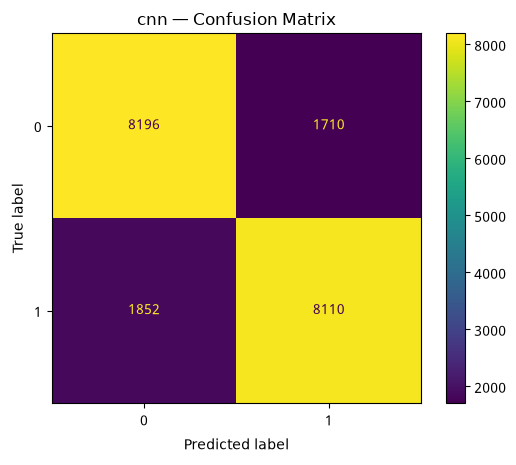

In [27]:
cnn_model = CNNClassifier(VOCAB_SIZE_ACTUAL, EMBED_DIM, num_filters=100, kernel_sizes=(3, 4, 5), pad_idx=PAD_IDX)
cnn_model = train_torch_model(cnn_model, "cnn", train_loader, val_loader, epochs=5)

y_true, y_pred, y_proba = get_torch_predictions(cnn_model, test_loader)
all_metrics["cnn"] = evaluate_from_predictions("cnn", y_true, y_pred, y_proba)

## 9. BanglaBERT

Fine-tunes `csebuetnlp/banglabert` (`AutoModelForSequenceClassification`, 2 labels) for a small number of epochs — appropriate for a free-tier Colab GPU/session limit. Same load-if-exists checkpointing as the rest of the notebook, using `save_pretrained`/`from_pretrained` against a Drive folder instead of a single file.

In [28]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BANGLABERT_NAME = "csebuetnlp/banglabert"
BANGLABERT_DIR = os.path.join(MODELS_DIR, "banglabert")
BERT_EPOCHS = 2

bert_tokenizer = AutoTokenizer.from_pretrained(
    BANGLABERT_DIR if os.path.exists(BANGLABERT_DIR) else BANGLABERT_NAME
)

bert_token_counts = [len(ids) for ids in bert_tokenizer(list(X_train))["input_ids"]]
BERT_MAX_LEN = int(np.percentile(bert_token_counts, 95))
BERT_MAX_LEN = min(max(BERT_MAX_LEN, 16), 128)
print(f"BERT_MAX_LEN (95th percentile of training length in BanglaBERT tokens, clamped to [16, 128]): {BERT_MAX_LEN}")


class BertTextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx], truncation=True, padding="max_length",
            max_length=self.max_len, return_tensors="pt",
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


bert_train_loader = DataLoader(
    BertTextDataset(X_train, y_train.to_numpy(), bert_tokenizer, BERT_MAX_LEN), batch_size=16, shuffle=True
)
bert_val_loader = DataLoader(
    BertTextDataset(X_val, y_val.to_numpy(), bert_tokenizer, BERT_MAX_LEN), batch_size=32
)
bert_test_loader = DataLoader(
    BertTextDataset(X_test, y_test.to_numpy(), bert_tokenizer, BERT_MAX_LEN), batch_size=32
)

BERT_MAX_LEN (95th percentile of training length in BanglaBERT tokens, clamped to [16, 128]): 55


In [29]:
if os.path.exists(BANGLABERT_DIR) and not FORCE_RETRAIN:
    bert_model = AutoModelForSequenceClassification.from_pretrained(BANGLABERT_DIR).to(device)
    print("Loaded fine-tuned BanglaBERT from Drive.")
else:
    bert_model = AutoModelForSequenceClassification.from_pretrained(BANGLABERT_NAME, num_labels=2).to(device)
    optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)

    for epoch in range(BERT_EPOCHS):
        bert_model.train()
        train_loss = 0.0
        for batch in bert_train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            outputs = bert_model(**batch)
            outputs.loss.backward()
            optimizer.step()
            train_loss += outputs.loss.item() * batch["labels"].size(0)

        bert_model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in bert_val_loader:
                batch = {k: v.to(device) for k, v in batch.items()}
                val_loss += bert_model(**batch).loss.item() * batch["labels"].size(0)

        print(
            f"[banglabert] epoch {epoch + 1}/{BERT_EPOCHS} "
            f"train_loss={train_loss / len(bert_train_loader.dataset):.4f} "
            f"val_loss={val_loss / len(bert_val_loader.dataset):.4f}"
        )

    bert_model.save_pretrained(BANGLABERT_DIR)
    bert_tokenizer.save_pretrained(BANGLABERT_DIR)
    print("Fine-tuned and saved BanglaBERT to Drive.")

[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[banglabert] epoch 1/2 train_loss=0.3559 val_loss=0.3176
[banglabert] epoch 2/2 train_loss=0.2719 val_loss=0.3169


Fine-tuned and saved BanglaBERT to Drive.



=== banglabert ===
accuracy: 0.8643
precision: 0.8642
recall: 0.8654
f1: 0.8648
roc_auc: 0.9424


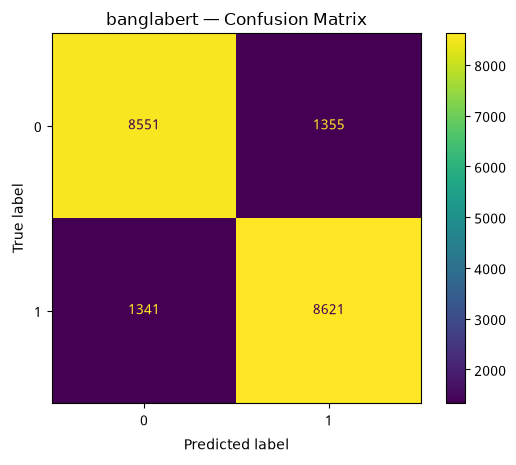

In [30]:
def get_bert_predictions(model, loader):
    model.eval()
    y_true, y_pred, y_proba = [], [], []
    with torch.no_grad():
        for batch in loader:
            labels = batch.pop("labels")
            batch = {k: v.to(device) for k, v in batch.items()}
            proba = torch.softmax(model(**batch).logits, dim=1)[:, 1].cpu().numpy()
            y_true.extend(labels.numpy().tolist())
            y_proba.extend(proba.tolist())
            y_pred.extend((proba >= 0.5).astype(int).tolist())
    return np.array(y_true), np.array(y_pred), np.array(y_proba)


y_true, y_pred, y_proba = get_bert_predictions(bert_model, bert_test_loader)
all_metrics["banglabert"] = evaluate_from_predictions("banglabert", y_true, y_pred, y_proba)

## 10. Explainability (Deep Learning Models)

SHAP/LIME are skipped here (per project scope — poor/slow support for custom nets and transformer internals). Instead, all 4 deep models are explained with Captum's **Layer Integrated Gradients**, attributing the prediction back to the embedding layer — a single method applied uniformly to RNN/LSTM/CNN's `nn.Embedding` and to BanglaBERT's input embeddings, giving per-word signed importance scores comparable in shape to the LIME/SHAP output from Section 7.

### 10.1 RNN / LSTM / CNN

In [31]:
from captum.attr import LayerIntegratedGradients


def explain_custom_model(model, name, text, n_steps=50):
    model.eval()
    tokens = tokenize_bn(text)[:MAX_LEN]
    ids = [vocab.get(t, UNK_IDX) for t in tokens]
    ids += [PAD_IDX] * (MAX_LEN - len(ids))
    input_ids = torch.tensor([ids], dtype=torch.long).to(device)
    baseline_ids = torch.full_like(input_ids, PAD_IDX)

    def forward_fn(inp):
        return torch.sigmoid(model(inp))

    lig = LayerIntegratedGradients(forward_fn, model.embedding)
    with torch.backends.cudnn.flags(enabled=False):
        attributions = lig.attribute(input_ids, baselines=baseline_ids, n_steps=n_steps)
    word_attrs = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()
    word_attrs = word_attrs[: len(tokens)]
    word_attrs = word_attrs / (np.abs(word_attrs).max() + 1e-12)

    print(f"\n--- Captum LayerIntegratedGradients: {name} ---")
    print(f"Text: {text}")
    for tok, score in zip(tokens, word_attrs):
        print(f"  {tok}: {score:+.4f}")
    return tokens, word_attrs


for model_name, model_obj in [("rnn", rnn_model), ("lstm", lstm_model), ("cnn", cnn_model)]:
    for text in sample_texts:
        explain_custom_model(model_obj, model_name, text)


--- Captum LayerIntegratedGradients: rnn ---
Text: বাকের ভাই এর মত নিশো ভাইয়ের এই চরিত্র টা অনেক অনেক ভালো লেগেছে আসলেই নাটকটা বাস্তব পরিস্থিতি তুলে ধরেছে বড়দের অন্যায় কাজের প্রতিবাদ করাটা যদি বেয়াদবি হয় তবে কম বয়সী পুলিশ কি বুড়া চোর রে ধরতে পারবে না দারুন একটা কন্সেপ্ট নিয়ে বানিয়েছে নাটক টা মূলত এমন বেয়াদব ছেলেদের দরকার আছে সমাজে বাকের ভাই ও তন্ময় এর মত প্রতিবাদি লোক গুলা সব সময়ই অপরাধী হয় সমাজের কাছে
  বাকের: +1.0000
  ভাই: -0.5593
  এর: +0.0247
  মত: +0.1280
  নিশো: +0.0825
  ভাইয়ের: +0.1895
  এই: -0.0679
  চরিত্র: +0.0229
  টা: -0.0395
  অনেক: -0.1319
  অনেক: -0.2087
  ভালো: -0.0173
  লেগেছে: +0.0459
  আসলেই: +0.1444
  নাটকটা: +0.0437
  বাস্তব: -0.0241
  পরিস্থিতি: -0.0628
  তুলে: +0.0117
  ধরেছে: -0.1190
  বড়দের: +0.0072
  অন্যায়: +0.0511
  কাজের: +0.0022
  প্রতিবাদ: -0.0166
  করাটা: -0.0809
  যদি: +0.1751
  বেয়াদবি: -0.0332
  হয়: +0.0140
  তবে: +0.1400
  কম: +0.0883
  বয়সী: -0.0973
  পুলিশ: +0.1926
  কি: +0.1836
  বুড়া: -0.0477
  চোর: -0.0370
  রে: -0.1049
  

### 10.2 BanglaBERT

In [32]:
def explain_bert(model, tokenizer, text, target=1, n_steps=50):
    model.eval()
    enc = tokenizer(text, truncation=True, padding="max_length", max_length=BERT_MAX_LEN, return_tensors="pt")
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)

    keep_ids = torch.tensor([tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id], device=device)
    baseline_ids = torch.where(
        torch.isin(input_ids, keep_ids), input_ids, torch.full_like(input_ids, tokenizer.pad_token_id)
    )

    def forward_fn(inp_ids, attn_mask):
        logits = model(input_ids=inp_ids, attention_mask=attn_mask).logits
        return torch.softmax(logits, dim=1)[:, target]

    lig = LayerIntegratedGradients(forward_fn, model.get_input_embeddings())
    attributions = lig.attribute(
        inputs=input_ids, baselines=baseline_ids,
        additional_forward_args=(attention_mask,), n_steps=n_steps,
    )
    word_attrs = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()
    word_attrs = word_attrs / (np.abs(word_attrs).max() + 1e-12)

    tokens = tokenizer.convert_ids_to_tokens(input_ids.squeeze(0).cpu().tolist())
    print(f"\n--- Captum LayerIntegratedGradients: banglabert ---")
    print(f"Text: {text}")
    for tok, score in zip(tokens, word_attrs):
        if tok == tokenizer.pad_token:
            continue
        print(f"  {tok}: {score:+.4f}")
    return tokens, word_attrs


for text in sample_texts:
    explain_bert(bert_model, bert_tokenizer, text)


--- Captum LayerIntegratedGradients: banglabert ---
Text: বাকের ভাই এর মত নিশো ভাইয়ের এই চরিত্র টা অনেক অনেক ভালো লেগেছে আসলেই নাটকটা বাস্তব পরিস্থিতি তুলে ধরেছে বড়দের অন্যায় কাজের প্রতিবাদ করাটা যদি বেয়াদবি হয় তবে কম বয়সী পুলিশ কি বুড়া চোর রে ধরতে পারবে না দারুন একটা কন্সেপ্ট নিয়ে বানিয়েছে নাটক টা মূলত এমন বেয়াদব ছেলেদের দরকার আছে সমাজে বাকের ভাই ও তন্ময় এর মত প্রতিবাদি লোক গুলা সব সময়ই অপরাধী হয় সমাজের কাছে
  [CLS]: +0.0000
  বাকের: -0.1976
  ভাই: +0.1117
  এর: +0.0889
  মত: -0.0288
  নিশ: -0.0843
  ##ো: +0.0003
  ভাইয়ের: -0.1056
  এই: -0.1651
  চরিত্র: -0.3697
  টা: -0.3543
  অনেক: -0.1894
  অনেক: -0.0587
  ভালো: -0.1523
  লেগেছে: -0.0537
  আসলেই: +0.0146
  নাটক: -0.4215
  ##টা: -0.1529
  বাস্তব: +0.0318
  পরিস্থিতি: -0.1344
  তুলে: +0.1307
  ধরেছে: +0.0612
  বড়দের: -0.4892
  অন্যায়: +0.1715
  কাজের: +0.0585
  প্রতিবাদ: +0.2660
  করাটা: +0.0946
  যদি: -0.0306
  বেয়াদ: +0.0337
  ##বি: -0.0257
  হয়: +0.0241
  তবে: -0.0126
  কম: +0.0669
  বয়সী: -0.1695
  পুলিশ: +0.8

## 11. K-Means Clustering (Unsupervised Exploration)

K-Means is **not** treated as another supervised classifier in the Section 12 comparison table — clustering has no notion of a target label to fit against. Instead, this section asks a different question: does Hate vs. Not-Hate emerge as a *structural* property of the TF-IDF space on its own, without ever being told the labels? Measured via silhouette score (cluster cohesion/separation) and Adjusted Rand Index (agreement with the true labels). Clustering runs on a 100-dimensional TruncatedSVD (LSA) projection of the TF-IDF features rather than all 20,000 columns, which is much faster and the standard approach for text.

### 11.1 Choosing k (elbow method)

Trained and saved model to /content/drive/MyDrive/bengali_hate_speech/models/lsa_svd100.joblib


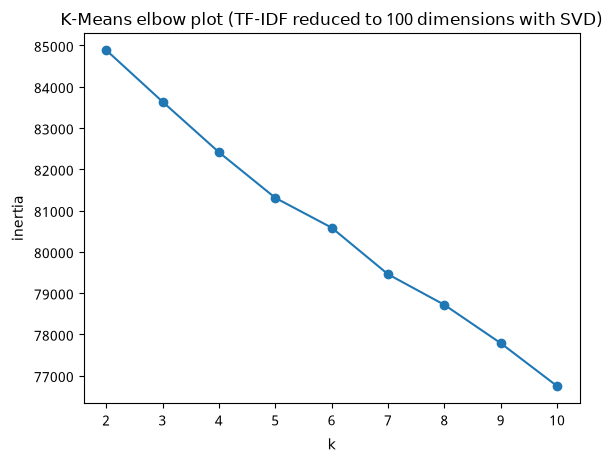

In [33]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

def train_lsa():
    m = make_pipeline(TruncatedSVD(n_components=100, random_state=SEED), Normalizer(copy=False))
    m.fit(X_train_tfidf)
    return m

lsa_model = load_or_train("lsa_svd100.joblib", train_lsa)
X_train_lsa = lsa_model.transform(X_train_tfidf)
X_test_lsa = lsa_model.transform(X_test_tfidf)

k_range = range(2, 11)
inertias = [KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_train_lsa).inertia_ for k in k_range]

plt.plot(list(k_range), inertias, marker="o")
plt.xlabel("k")
plt.ylabel("inertia")
plt.title("K-Means elbow plot (TF-IDF reduced to 100 dimensions with SVD)")
plt.show()

### 11.2 Fit K-Means (k=2, matching Hate / Not-Hate) and score against true labels

In [34]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

def train_kmeans():
    m = KMeans(n_clusters=2, random_state=SEED, n_init=10)
    m.fit(X_train_lsa)
    return m

kmeans_model = load_or_train("kmeans_lsa100.joblib", train_kmeans)

train_clusters = kmeans_model.predict(X_train_lsa)
test_clusters = kmeans_model.predict(X_test_lsa)

sil = silhouette_score(X_train_lsa, train_clusters, sample_size=2000, random_state=SEED)
ari = adjusted_rand_score(y_test, test_clusters)

print(f"Silhouette score (train, sampled): {sil:.4f}")
print(f"Adjusted Rand Index vs. true labels (test): {ari:.4f}")

crosstab = pd.crosstab(pd.Series(test_clusters, name="cluster"), pd.Series(y_test.to_numpy(), name="true_label"))
print("\nCluster vs. true label crosstab:")
display(crosstab)

with open(os.path.join(RESULTS_DIR, "kmeans_metrics.json"), "w") as f:
    json.dump({"silhouette_score": sil, "adjusted_rand_index": ari}, f, indent=2)

Trained and saved model to /content/drive/MyDrive/bengali_hate_speech/models/kmeans_lsa100.joblib
Silhouette score (train, sampled): 0.0121
Adjusted Rand Index vs. true labels (test): 0.0008

Cluster vs. true label crosstab:


true_label,0,1
cluster,,
0,8384,8134
1,1522,1828


### 11.3 2D visualization (SVD projection)

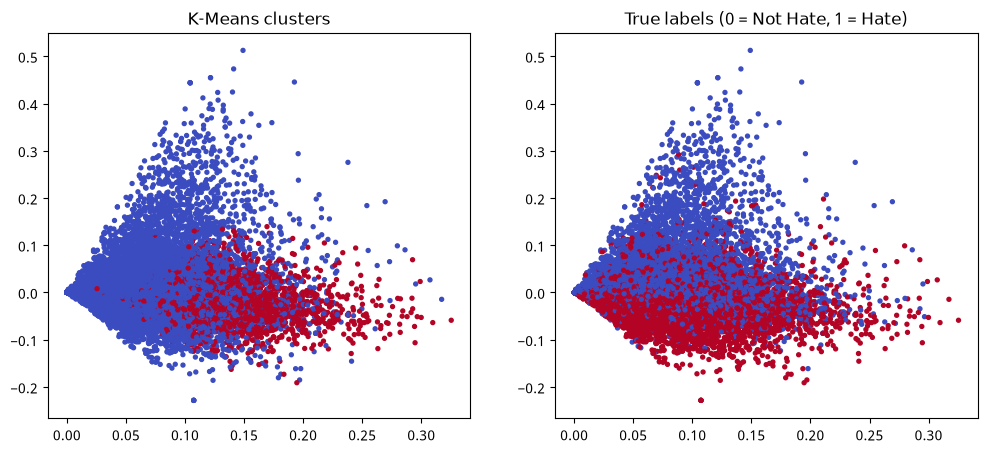

In [35]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=SEED)
test_2d = svd.fit_transform(X_test_tfidf)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(test_2d[:, 0], test_2d[:, 1], c=test_clusters, cmap="coolwarm", s=8)
axes[0].set_title("K-Means clusters")
axes[1].scatter(test_2d[:, 0], test_2d[:, 1], c=y_test.to_numpy(), cmap="coolwarm", s=8)
axes[1].set_title("True labels (0 = Not Hate, 1 = Hate)")
plt.show()

## 12. Model Comparison

Side-by-side metrics for every trained supervised model — the 4 classical models from Section 6 plus RNN/LSTM/CNN (Section 8) and BanglaBERT (Section 9). K-Means is excluded (see Section 11 note).

,accuracy,precision,recall,f1,roc_auc
banglabert,0.864304,0.864174,0.865388,0.864781,0.942416
cnn,0.820717,0.825866,0.814094,0.819937,0.904229
logistic_regression,0.823233,0.848724,0.787894,0.817179,0.906911
linear_svc,0.820062,0.842834,0.788095,0.814546,0.903054
multinomial_nb,0.800332,0.798229,0.80536,0.801779,0.89142
lstm,0.815382,0.875537,0.736499,0.800022,0.904422
rnn,0.678931,0.670928,0.705882,0.687962,0.745874
knn,0.609221,0.667582,0.43947,0.530024,0.666098


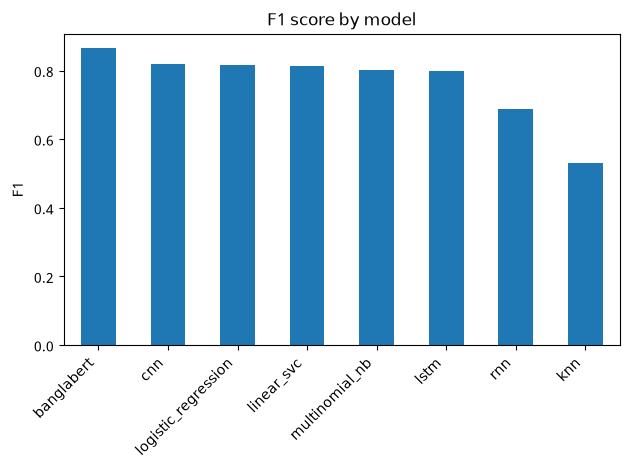

In [36]:
import pandas as pd

comparison_df = pd.DataFrame(all_metrics).T[["accuracy", "precision", "recall", "f1", "roc_auc"]]
comparison_df = comparison_df.sort_values("f1", ascending=False)
display(comparison_df)

comparison_df["f1"].plot(kind="bar", title="F1 score by model")
plt.ylabel("F1")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

comparison_df.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"))

## 13. Top Hate Words

Sorted Logistic Regression TF-IDF coefficients — the cleanest, most interpretable source for "words the model associates with Hate." Drives the adversarial injection test in Section 14.

নাস্তিক: +14.2833
মাগি: +10.5597
নাস্তিকের: +8.4852
খানকির: +8.3472
মাগী: +7.9772
কুত্তার: +7.7806
মাগির: +7.6382
খানকি: +7.5386
শালা: +7.4429
সালা: +7.0783
নাস্তিকদের: +6.2275
কুত্তা: +6.0571
জারজ: +5.9759
আবাল: +5.8809
মাদারচোদ: +5.7378
চোদা: +5.6784
শালার: +5.6668
মাদার: +5.6157
চুদি: +5.4343
সালার: +5.3859
কুলাঙ্গার: +5.3582
জানোয়ার: +5.3414
শয়তান: +5.3362
ছাগল: +5.2450
বেশ্যা: +5.0382
বোকাচোদা: +5.0364
জুতা: +5.0240
জানোয়ারের: +4.9548
মাগীর: +4.8599
পাছা: +4.8222


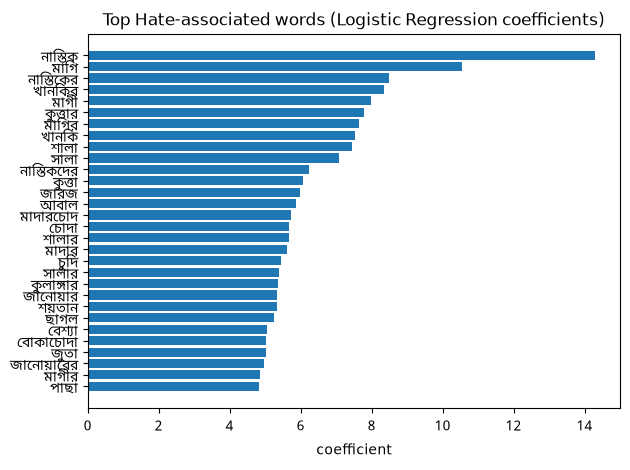

In [37]:
lr_feature_names = vectorizer.get_feature_names_out()
lr_coefs = lr_model.coef_[0]

TOP_N_HATE_WORDS = 30
top_hate_idx = np.argsort(lr_coefs)[::-1][:TOP_N_HATE_WORDS]
top_hate_words = [(lr_feature_names[i], lr_coefs[i]) for i in top_hate_idx]

for word, coef in top_hate_words:
    print(f"{word}: {coef:+.4f}")

plt.barh([w for w, _ in top_hate_words][::-1], [c for _, c in top_hate_words][::-1])
plt.title("Top Hate-associated words (Logistic Regression coefficients)")
plt.xlabel("coefficient")
plt.tight_layout()
plt.show()

## 14. Adversarial Word-Injection Test

Takes 10 Not-Hate test examples, appends one of the top 10 hate words from Section 13 to each (example *i* gets word *i*), and re-runs every pair through all 8 trained supervised models (Sections 6, 8 and 9) for a before/after comparison. A model's flip rate counts only the examples it first predicted as Not-Hate (`eligible`): an example it already called Hate has nothing to flip. K-Means is excluded — it has no notion of a Hate-probability to compare.

In [38]:
def predict_all_models(text):
    preds = {}

    tfidf_vec = vectorizer.transform([text])
    preds["logistic_regression"] = lr_model.predict_proba(tfidf_vec)[0, 1]
    preds["linear_svc"] = svc_model.predict_proba(tfidf_vec)[0, 1]
    preds["multinomial_nb"] = nb_model.predict_proba(tfidf_vec)[0, 1]
    preds["knn"] = knn_model.predict_proba(tfidf_vec)[0, 1]

    input_ids = torch.tensor([encode_text(text)], dtype=torch.long).to(device)
    for name, model in [("rnn", rnn_model), ("lstm", lstm_model), ("cnn", cnn_model)]:
        model.eval()
        with torch.no_grad():
            preds[name] = torch.sigmoid(model(input_ids)).item()

    bert_model.eval()
    enc = bert_tokenizer(text, truncation=True, padding="max_length", max_length=BERT_MAX_LEN, return_tensors="pt")
    enc = {k: v.to(device) for k, v in enc.items()}
    with torch.no_grad():
        preds["banglabert"] = torch.softmax(bert_model(**enc).logits, dim=1)[0, 1].item()

    return preds


N_ADVERSARIAL_EXAMPLES = 10

non_hate_examples = X_test[y_test == 0]
base_texts = non_hate_examples.sample(
    min(N_ADVERSARIAL_EXAMPLES, len(non_hate_examples)), random_state=SEED
).tolist()
injection_words = [word for word, _ in top_hate_words[:N_ADVERSARIAL_EXAMPLES]]

flip_columns, eligible_columns = [], []

for i, (base_text, injected_word) in enumerate(zip(base_texts, injection_words)):
    injected_text = f"{base_text} {injected_word}"
    before_preds = predict_all_models(base_text)
    after_preds = predict_all_models(injected_text)

    injection_comparison = pd.DataFrame({"before": before_preds, "after": after_preds})
    injection_comparison["delta"] = injection_comparison["after"] - injection_comparison["before"]
    injection_comparison["flipped_to_hate"] = (
        (injection_comparison["before"] < 0.5) & (injection_comparison["after"] >= 0.5)
    )

    print(f"\n=== Example {i + 1}/{len(base_texts)} ===")
    print(f"Base text: {base_text}")
    print(f"Injected word: {injected_word}")
    print(f"Injected text: {injected_text}")
    display(injection_comparison)

    flip_columns.append(injection_comparison["flipped_to_hate"])
    eligible_columns.append(injection_comparison["before"] < 0.5)

flip_summary = pd.DataFrame({
    "flipped": pd.concat(flip_columns, axis=1).sum(axis=1),
    "eligible": pd.concat(eligible_columns, axis=1).sum(axis=1),
})
flip_summary["flip_rate"] = flip_summary["flipped"] / flip_summary["eligible"].replace(0, np.nan)

print(f"\nFlip rate by model (Not-Hate -> Hate after injection), out of the {len(base_texts)} examples")
print("each model first predicted as Not-Hate ('eligible'):")
display(flip_summary.sort_values("flip_rate", ascending=False))


=== Example 1/10 ===
Base text: অর সাতি ছাছি
Injected word: নাস্তিক
Injected text: অর সাতি ছাছি নাস্তিক


,before,after,delta,flipped_to_hate
logistic_regression,0.368530,0.998555,0.630025,True
linear_svc,0.326821,0.998147,0.671326,True
multinomial_nb,0.604985,0.915374,0.310389,False
knn,0.600000,0.600000,0.000000,False
rnn,0.312261,0.218291,-0.093970,False
lstm,0.187121,0.986777,0.799657,True
cnn,0.456476,0.999707,0.543231,True
banglabert,0.041175,0.984543,0.943368,True



=== Example 2/10 ===
Base text: নাজমুল হাসান এর ভক্ত গুলা হাত তুলো
Injected word: মাগি
Injected text: নাজমুল হাসান এর ভক্ত গুলা হাত তুলো মাগি


,before,after,delta,flipped_to_hate
logistic_regression,0.339344,0.875136,0.535791,True
linear_svc,0.265065,0.857514,0.592450,True
multinomial_nb,0.258348,0.578205,0.319857,True
knn,0.200000,0.200000,0.000000,False
rnn,0.217837,0.220850,0.003013,False
lstm,0.008277,0.972307,0.964030,True
cnn,0.274829,0.999368,0.724539,True
banglabert,0.011242,0.994748,0.983506,True



=== Example 3/10 ===
Base text: অনেক বালো হবে
Injected word: নাস্তিকের
Injected text: অনেক বালো হবে নাস্তিকের


...

,before,after,delta,flipped_to_hate
logistic_regression,0.559654,0.959912,0.400259,False
linear_svc,0.818261,0.987453,0.169192,False
multinomial_nb,0.386707,0.712228,0.325521,True
knn,0.600000,0.400000,-0.200000,False
rnn,0.713416,0.716696,0.003280,False
lstm,0.823549,0.980311,0.156761,False
cnn,0.816846,0.998792,0.181946,False
banglabert,0.212164,0.959098,0.746935,True



=== Example 10/10 ===
Base text: ওড়না নম্বরে যোগাযোগ করা যাবে কি আমার সাথে কথা বলার জন্য কথা ছিল
Injected word: সালা
Injected text: ওড়না নম্বরে যোগাযোগ করা যাবে কি আমার সাথে কথা বলার জন্য কথা ছিল সালা


,before,after,delta,flipped_to_hate
logistic_regression,0.199299,0.465032,0.265733,False
linear_svc,0.180607,0.409917,0.229310,False
multinomial_nb,0.165865,0.264777,0.098912,False
knn,0.400000,0.400000,0.000000,False
rnn,0.342585,0.377949,0.035365,False
lstm,0.167502,0.633122,0.465621,True
cnn,0.307711,0.838243,0.530533,True
banglabert,0.257508,0.953599,0.696090,True



Flip rate by model (Not-Hate -> Hate after injection), out of the 10 examples
each model first predicted as Not-Hate ('eligible'):


,flipped,eligible,flip_rate
cnn,9,9,1.000000
banglabert,9,9,1.000000
linear_svc,8,9,0.888889
logistic_regression,7,8,0.875000
lstm,7,8,0.875000
multinomial_nb,5,7,0.714286
knn,2,8,0.250000
rnn,0,7,0.000000


## 15. Negation Analysis

Hate-speech papers typically report accuracy/F1 without testing whether a model's
prediction correctly reverses under negation — a common evaluation in general NLP
(sentiment analysis, NLI) but rarely applied here. TF-IDF/bag-of-words models have
no mechanism to let a negation token invert a hate word's contribution elsewhere in
the sentence; a contextual model like BanglaBERT, in principle, can. This section
hand-crafts (statement, negated-statement) pairs — several reusing words Section 13
already identified as top hate indicators — and checks, per model, how often the
predicted label correctly flips from Hate to Not-Hate once negation is added.

Only pairs whose original statement the model predicts as Hate count toward its rate (`eligible` in the table): if it misses the hate in the first place, that is an accuracy error, not a negation error.


=== Pair 1/13 ===
Positive: আমি তাকে ঘৃণা করি
Negated : আমি তাকে ঘৃণা করি না


,positive,negated,delta,negation_understood
logistic_regression,0.385974,0.529081,-0.143107,False
linear_svc,0.551555,0.717327,-0.165773,False
multinomial_nb,0.522488,0.596476,-0.073987,False
knn,0.400000,0.200000,0.200000,False
rnn,0.258255,0.281405,-0.023149,False
lstm,0.030647,0.049552,-0.018905,False
cnn,0.044856,0.125556,-0.080700,False
banglabert,0.141003,0.029915,0.111088,False



=== Pair 2/13 ===
Positive: আমি তোকে ঘৃণা করি
Negated : আমি তোকে ঘৃণা করি না


,positive,negated,delta,negation_understood
logistic_regression,0.554490,0.673427,-0.118937,False
linear_svc,0.660438,0.777969,-0.117532,False
multinomial_nb,0.735616,0.775138,-0.039522,False
knn,0.200000,0.600000,-0.400000,False
rnn,0.587787,0.600691,-0.012905,False
lstm,0.141299,0.153211,-0.011913,False
cnn,0.148612,0.394833,-0.246221,False
banglabert,0.442479,0.116775,0.325704,False



=== Pair 3/13 ===
Positive: তুমি একটা জারজ
Negated : তুমি জারজ না


...

,positive,negated,delta,negation_understood
logistic_regression,0.465224,0.358608,0.106616,False
linear_svc,0.485521,0.267651,0.217870,False
multinomial_nb,0.623813,0.585872,0.037942,False
knn,0.600000,0.800000,-0.200000,False
rnn,0.595463,0.492160,0.103303,True
lstm,0.028372,0.029070,-0.000698,False
cnn,0.249119,0.298882,-0.049763,False
banglabert,0.376885,0.220457,0.156428,False



=== Pair 13/13 ===
Positive: আমি ওদের প্রতি ঘৃণা পোষণ করি
Negated : আমি ওদের প্রতি ঘৃণা পোষণ করি না


,positive,negated,delta,negation_understood
logistic_regression,0.187173,0.316874,-0.129701,False
linear_svc,0.208545,0.363869,-0.155325,False
multinomial_nb,0.274179,0.363901,-0.089721,False
knn,0.200000,0.800000,-0.600000,False
rnn,0.361412,0.334572,0.026840,False
lstm,0.005484,0.011309,-0.005825,False
cnn,0.034883,0.038969,-0.004086,False
banglabert,0.337218,0.109366,0.227852,False



Negation sensitivity by model (Hate -> Not-Hate correctly after negation), out of the 13
pairs whose original statement each model predicted as Hate ('eligible'):


,understood,eligible,flip_rate
rnn,1,10,0.1
logistic_regression,0,9,0.0
multinomial_nb,0,11,0.0
linear_svc,0,10,0.0
knn,0,9,0.0
lstm,0,8,0.0
cnn,0,8,0.0
banglabert,0,8,0.0


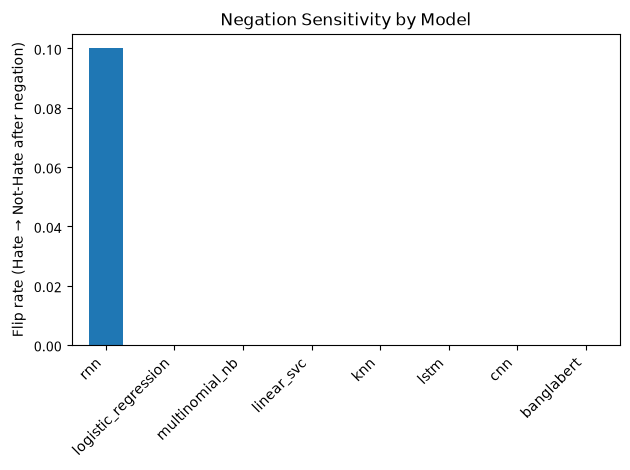

In [39]:
negation_pairs = [
    ("আমি তাকে ঘৃণা করি", "আমি তাকে ঘৃণা করি না"),
    ("আমি তোকে ঘৃণা করি", "আমি তোকে ঘৃণা করি না"),
    ("তুমি একটা জারজ", "তুমি জারজ না"),
    ("সে একটা কুত্তার বাচ্চা", "সে কুত্তার বাচ্চা না"),
    ("তুই একটা বেশ্যা", "তুই বেশ্যা না"),
    ("তোরা সব নাস্তিকের বাচ্চা", "তোরা নাস্তিকের বাচ্চা না"),
    ("সে একটা শয়তান", "সে শয়তান না"),
    ("তুমি একটা আবাল", "তুমি আবাল না"),
    ("ও একটা ছাগল", "ও ছাগল না"),
    ("তুই একটা মাগি", "তুই মাগি না"),
    ("তোমাকে আমি অপছন্দ করি", "তোমাকে আমি অপছন্দ করি না"),
    ("সে একটা খারাপ মানুষ", "সে খারাপ মানুষ না"),
    ("আমি ওদের প্রতি ঘৃণা পোষণ করি", "আমি ওদের প্রতি ঘৃণা পোষণ করি না"),
]

negation_rows, eligible_rows = [], []
for i, (pos_text, neg_text) in enumerate(negation_pairs):
    pos_preds = predict_all_models(clean_text(pos_text))
    neg_preds = predict_all_models(clean_text(neg_text))

    pair_df = pd.DataFrame({"positive": pos_preds, "negated": neg_preds})
    pair_df["delta"] = pair_df["positive"] - pair_df["negated"]
    pair_df["negation_understood"] = (pair_df["positive"] >= 0.5) & (pair_df["negated"] < 0.5)

    print(f"\n=== Pair {i + 1}/{len(negation_pairs)} ===")
    print(f"Positive: {pos_text}")
    print(f"Negated : {neg_text}")
    display(pair_df)

    negation_rows.append(pair_df["negation_understood"])
    eligible_rows.append(pair_df["positive"] >= 0.5)

negation_summary = pd.DataFrame({
    "understood": pd.concat(negation_rows, axis=1).sum(axis=1),
    "eligible": pd.concat(eligible_rows, axis=1).sum(axis=1),
})
negation_summary["flip_rate"] = negation_summary["understood"] / negation_summary["eligible"].replace(0, np.nan)
negation_summary = negation_summary.sort_values("flip_rate", ascending=False)

print(f"\nNegation sensitivity by model (Hate -> Not-Hate correctly after negation), out of the {len(negation_pairs)}")
print("pairs whose original statement each model predicted as Hate ('eligible'):")
display(negation_summary)

negation_summary.to_csv(os.path.join(RESULTS_DIR, "negation_analysis_summary.csv"))

ax = negation_summary["flip_rate"].plot(kind="bar", legend=False)
ax.set_title("Negation Sensitivity by Model")
ax.set_ylabel("Flip rate (Hate → Not-Hate after negation)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()